# Lab 3: Classification of Ticket Escalation

**Goal:** build and evaluate binary classifiers for a synthetic ticket-escalation dataset, and choose metrics and thresholds based on the *cost* of mistakes (not just a high score).

Models: majority-class baseline, Logistic Regression, Linear Discriminant Analysis (LDA), k-NN (k=15, then tuned).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay
)

pd.set_option("display.precision", 3)

## 1. Load and inspect the data

In [2]:
df = pd.read_csv("classification_escalation.csv")
print(df.shape)
display(df.head())
print(df.info())
print(df["escalated"].value_counts(normalize=True).rename("proportion"))

(900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None
escalated
0    0.793
1    0.207
Name: proportion, dtype: float64


In [3]:
print("Missing values per column:")
print(df.isna().sum())
print()
print("Missing as % of rows:")
print((df.isna().mean() * 100).round(1))
print()
display(df.describe())
print(df["priority"].value_counts(dropna=False))
print(df["channel"].value_counts(dropna=False))

Missing values per column:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

Missing as % of rows:
complexity_score          0.0
team_experience_years     3.4
priority                  2.0
channel                   0.0
customer_tenure_months    2.4
escalated                 0.0
dtype: float64



,complexity_score,team_experience_years,customer_tenure_months,escalated
count,900.000,869.000,878.000,900.000
mean,5.433,4.443,22.553,0.207
std,2.835,2.138,14.888,0.405
min,1.000,0.000,0.900,0.000
25%,3.000,2.900,11.400,0.000
50%,5.000,4.400,19.550,0.000
75%,8.000,5.900,30.150,0.000
max,10.000,11.800,97.400,1.000


priority
low       434
medium    306
high      142
NaN        18
Name: count, dtype: int64
channel
email    424
web      304
phone    172
Name: count, dtype: int64


**Observations**

- 900 rows and 6 columns (5 predictors + the target `escalated`).
- Only about 20.7% of tickets are escalated, so the classes are **imbalanced** (roughly 4 non-escalated tickets for every escalated one).
- Missing values are in `team_experience_years` (31), `priority` (18) and `customer_tenure_months` (22). The assignment says this is by design, so I will handle it with imputation inside the pipeline (so that imputation values are learned from the training data only, avoiding leakage).

## 2. Why classification, and what is the positive class?

This is a **classification** problem because the target `escalated` is a category with two possible values (0 or 1), not a continuous number. We want to predict which class a new ticket belongs to (and the probability of it).

The **positive class is `escalated = 1`**. This is the class we care about finding, because missing an escalated ticket (a false negative) is more costly than raising an unnecessary alarm (a false positive). So *recall* and *precision* are both defined with respect to escalated tickets.

## 3. Train/test split

In [4]:
X = df.drop(columns="escalated")
y = df["escalated"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train prevalence:", round(y_train.mean(), 4))
print("Test prevalence: ", round(y_test.mean(), 4))
print("Positives in test set:", y_test.sum(), "of", len(y_test))

Train: (675, 5)  Test: (225, 5)
Train prevalence: 0.2074
Test prevalence:  0.2044
Positives in test set: 46 of 225


Stratifying keeps the escalation rate almost the same in train and test, which matters because the positive class is the minority.

## 4. Preprocessing pipelines

In [5]:
num_cols = ["complexity_score", "team_experience_years", "customer_tenure_months"]
cat_cols = ["priority", "channel"]

num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

Scaling matters especially for k-NN, since it uses distances, and also helps logistic regression converge.

## 5. Fit the models and compare

In [6]:
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "LDA": LinearDiscriminantAnalysis(),
    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15),
}

fitted = {}
rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    pred = pipe.predict(X_test)
    # ROC-AUC only where we have probability scores (not meaningful for the constant baseline)
    if name == "Majority baseline":
        auc = np.nan
    else:
        auc = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": auc,
    })

results = pd.DataFrame(rows).set_index("Model")
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Majority baseline,0.796,0.00,0.000,0.000,NaN
Logistic Regression,0.822,0.75,0.196,0.310,0.811
LDA,0.822,0.75,0.196,0.310,0.809
k-NN (k=15),0.796,0.50,0.087,0.148,0.705


In [7]:
# Classification reports for a closer look (default 0.5 threshold)
for name, pipe in fitted.items():
    print("=====", name, "=====")
    print(classification_report(y_test, pipe.predict(X_test), zero_division=0))

===== Majority baseline =====
              precision    recall  f1-score   support

           0       0.80      1.00      0.89       179
           1       0.00      0.00      0.00        46

    accuracy                           0.80       225
   macro avg       0.40      0.50      0.44       225
weighted avg       0.63      0.80      0.70       225

===== Logistic Regression =====
              precision    recall  f1-score   support

           0       0.83      0.98      0.90       179
           1       0.75      0.20      0.31        46

    accuracy                           0.82       225
   macro avg       0.79      0.59      0.60       225
weighted avg       0.81      0.82      0.78       225

===== LDA =====
              precision    recall  f1-score   support

           0       0.83      0.98      0.90       179
           1       0.75      0.20      0.31        46

    accuracy                           0.82       225
   macro avg       0.79      0.59      0.60       

**Reading the table**

- **Why accuracy alone is misleading:** the majority baseline never predicts an escalation and still gets about 79.6% accuracy, simply because ~79% of tickets are not escalated. It has precision, recall and F1 of 0. A model can look good on accuracy while being useless at finding the cases we care about.
- **Strongest recall:** at the default 0.5 threshold, Logistic Regression and LDA are tied at 0.196 recall, ahead of k-NN (0.087) and the baseline (0). So recall is poor for every model at the default threshold.
- **Strongest precision / F1:** Logistic Regression and LDA are also tied for precision (0.75) and F1 (0.31). The ROC-AUC for Logistic Regression (about 0.811) is marginally higher than LDA (about 0.809), and both are well above k-NN (about 0.705).
- All the models are weak at 0.5 because the positive class is rare, so the predicted probabilities seldom pass 0.5. This is the reason we look at lowering the threshold next.

## 6. Confusion matrix and ROC curve for Logistic Regression

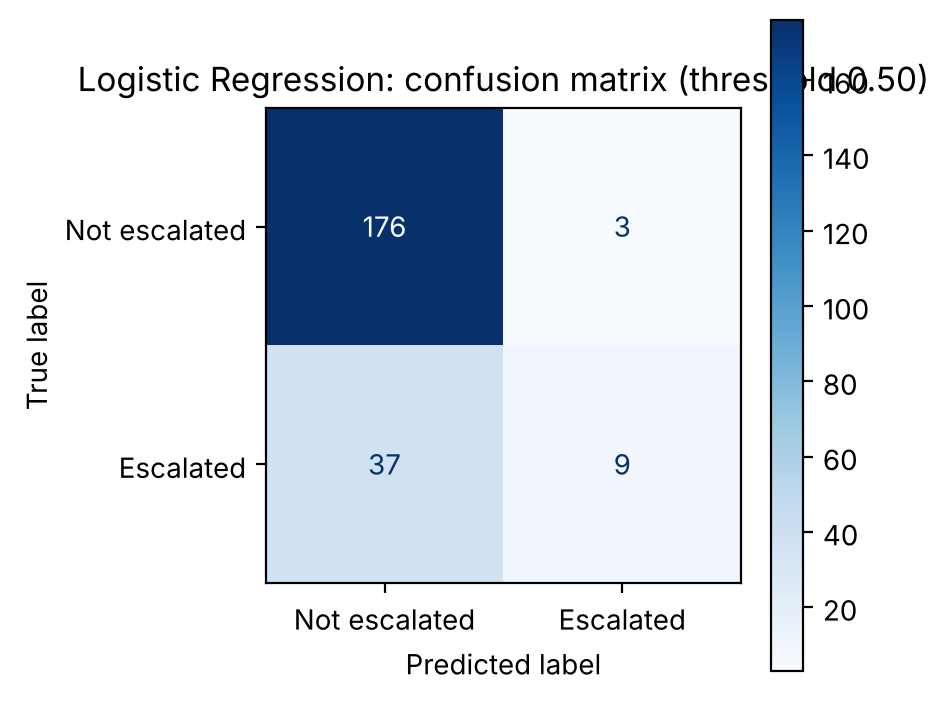

TN=176  FP=3  FN=37  TP=9


In [8]:
lr_pipe = fitted["Logistic Regression"]
lr_pred = lr_pipe.predict(X_test)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, lr_pred, display_labels=["Not escalated", "Escalated"], cmap="Blues", ax=ax
)
ax.set_title("Logistic Regression: confusion matrix (threshold 0.50)")
plt.tight_layout()
plt.savefig("figures/confusion_matrix_lr.png", dpi=150)
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, lr_pred).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

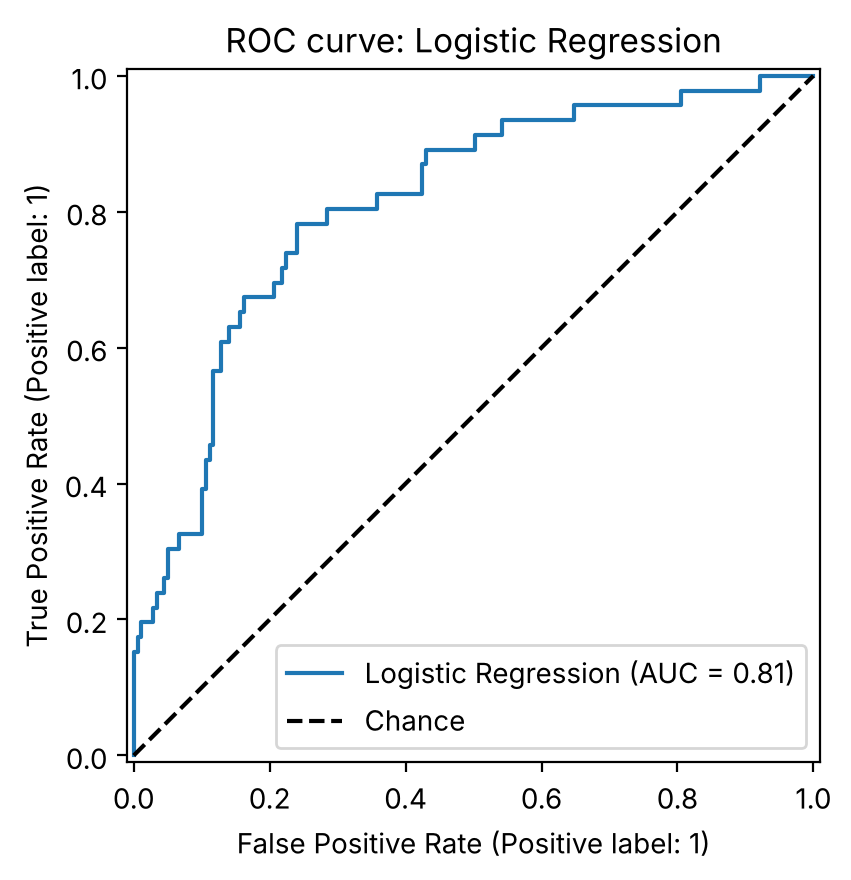

In [9]:
fig, ax = plt.subplots(figsize=(5, 4.5))
RocCurveDisplay.from_estimator(lr_pipe, X_test, y_test, name="Logistic Regression", ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set_title("ROC curve: Logistic Regression")
ax.legend()
plt.tight_layout()
plt.savefig("figures/roc_curve_lr.png", dpi=150)
plt.show()

At the 0.50 threshold, the logistic regression correctly finds only 9 of the 46 escalated tickets (TP = 9) and misses 37 (FN = 37), while raising only 3 false alarms. The ROC curve is clearly above the diagonal (AUC about 0.81), so the model does rank escalated tickets higher than non-escalated ones. The problem is not the ranking, it is the threshold being too high for a rare positive class.

## 7. Threshold analysis

In [10]:
probs = lr_pipe.predict_proba(X_test)[:, 1]
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
COST_FN, COST_FP = 5, 1

trows = []
for t in thresholds:
    pred_t = (probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_t).ravel()
    trows.append({
        "Threshold": t,
        "Precision": precision_score(y_test, pred_t, zero_division=0),
        "Recall": recall_score(y_test, pred_t),
        "F1": f1_score(y_test, pred_t),
        "FP": fp,
        "FN": fn,
        "Cost (5*FN + FP)": COST_FN * fn + COST_FP * fp,
    })

thr_table = pd.DataFrame(trows).set_index("Threshold")
thr_table

,Precision,Recall,F1,FP,FN,Cost (5*FN + FP)
Threshold,,,,,,
0.2,0.429,0.783,0.554,48,10,98
0.3,0.549,0.609,0.577,23,18,113
0.4,0.571,0.261,0.358,9,34,179
0.5,0.750,0.196,0.310,3,37,188
0.6,1.000,0.065,0.122,0,43,215
0.7,0.000,0.000,0.000,0,46,230


Threshold with the lowest cost on the test set: 0.2
Cost at that threshold: 98
Cost at default 0.50:  188


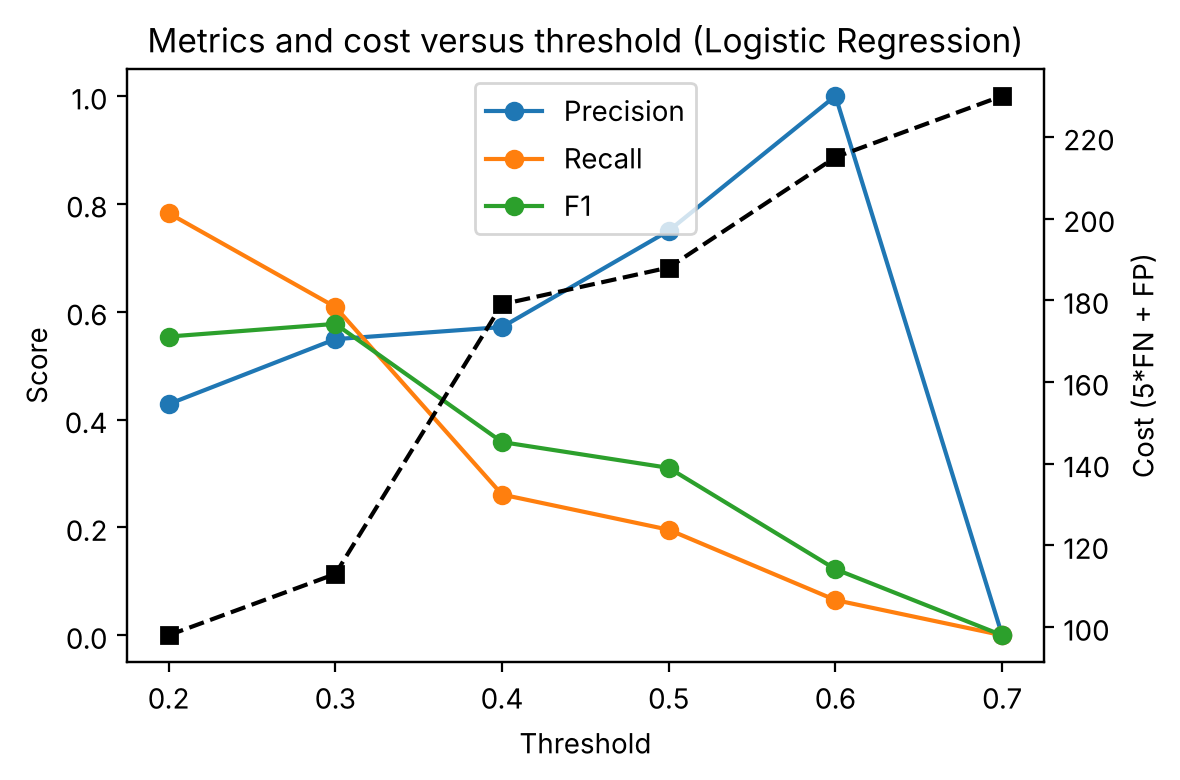

In [11]:
best_t = thr_table["Cost (5*FN + FP)"].idxmin()
print("Threshold with the lowest cost on the test set:", best_t)
print("Cost at that threshold:", thr_table.loc[best_t, "Cost (5*FN + FP)"])
print("Cost at default 0.50: ", thr_table.loc[0.5, "Cost (5*FN + FP)"])

fig, ax1 = plt.subplots(figsize=(6, 4))
ax1.plot(thr_table.index, thr_table["Precision"], marker="o", label="Precision")
ax1.plot(thr_table.index, thr_table["Recall"], marker="o", label="Recall")
ax1.plot(thr_table.index, thr_table["F1"], marker="o", label="F1")
ax1.set_xlabel("Threshold")
ax1.set_ylabel("Score")
ax1.legend(loc="upper center")
ax2 = ax1.twinx()
ax2.plot(thr_table.index, thr_table["Cost (5*FN + FP)"], "k--", marker="s", label="Cost")
ax2.set_ylabel("Cost (5*FN + FP)")
ax1.set_title("Metrics and cost versus threshold (Logistic Regression)")
plt.tight_layout()
plt.savefig("figures/threshold_tradeoff.png", dpi=150)
plt.show()

**What changes when the threshold is lowered?** More tickets are classified as escalated. Recall goes up (0.20 at 0.50, to 0.78 at 0.20) and false negatives fall (37 down to 10), but precision drops (0.75 to 0.43) and false positives rise (3 up to 48). At 0.70 the model predicts nothing as positive, so precision shows as 0 and recall is 0. Threshold choice is therefore a trade-off between the two kinds of errors.

**Which threshold minimizes 5×FN + FP?** Among the thresholds tested, **0.20** has the lowest cost (98, versus 188 at the default 0.50). F1 is actually highest at 0.30, which shows that the F1-best threshold is not the same as the cost-best threshold: F1 treats FP and FN as equally bad, but our cost function says a miss is five times worse.

**Why might this estimate be optimistic?** I looked at the test set to pick the threshold, so the test set has influenced a modelling decision. If I keep comparing many thresholds (or models) on the same test set, I will tend to pick the one that happens to look best on this particular sample, and the true cost on new tickets will probably be higher. With only 46 positive cases the cost is also noisy. A better approach is to choose the threshold using cross-validation on the training data and only use the test set once for a final check (I do this below as a sanity check).

### Sanity check: choosing the threshold from the training data only

In [12]:
# out-of-fold probabilities on the TRAINING set (5-fold, stratified)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs = cross_val_predict(
    Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=1000))]),
    X_train, y_train, cv=skf, method="predict_proba"
)[:, 1]

grid = np.round(np.arange(0.05, 0.71, 0.01), 2)
oof_costs = []
for t in grid:
    p_t = (oof_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, p_t).ravel()
    oof_costs.append(COST_FN * fn + COST_FP * fp)

best_cv_t = grid[int(np.argmin(oof_costs))]
print("Threshold with lowest cost on training out-of-fold predictions:", best_cv_t)

# now apply that threshold ONCE on the test set
pred_cv = (probs >= best_cv_t).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_cv).ravel()
print(f"Test set at threshold {best_cv_t}: FP={fp}, FN={fn}, cost={5*fn+fp}, "
      f"precision={precision_score(y_test, pred_cv):.3f}, recall={recall_score(y_test, pred_cv):.3f}")

Threshold with lowest cost on training out-of-fold predictions: 0.16
Test set at threshold 0.16: FP=71, FN=8, cost=111, precision=0.349, recall=0.826


The threshold picked from the training data alone (0.16) is also far below 0.50, which gives me more confidence that a low threshold really is better for this cost ratio and not just a quirk of the test sample. Its test cost (111) is a bit higher than the 98 I got by picking 0.20 directly on the test set, which is a small example of how choosing on the test set gives an optimistic number. The honest estimate of the cost is closer to 110 than 98.

## 8. Cross-validation and tuning k for k-NN

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_pipe = Pipeline([("prep", preprocess), ("model", KNeighborsClassifier())])
param_grid = {"model__n_neighbors": [5, 9, 15, 21, 31]}

grid_search = GridSearchCV(knn_pipe, param_grid, scoring="f1", cv=cv)
grid_search.fit(X_train, y_train)

cv_res = pd.DataFrame({
    "k": param_grid["model__n_neighbors"],
    "mean CV F1": grid_search.cv_results_["mean_test_score"],
    "std CV F1": grid_search.cv_results_["std_test_score"],
}).set_index("k")
display(cv_res)
print("Best k:", grid_search.best_params_["model__n_neighbors"],
      "| best mean CV F1:", round(grid_search.best_score_, 3))

,mean CV F1,std CV F1
k,,
5,0.243,0.095
9,0.198,0.065
15,0.160,0.065
21,0.146,0.056
31,0.112,0.040


Best k: 5 | best mean CV F1: 0.243


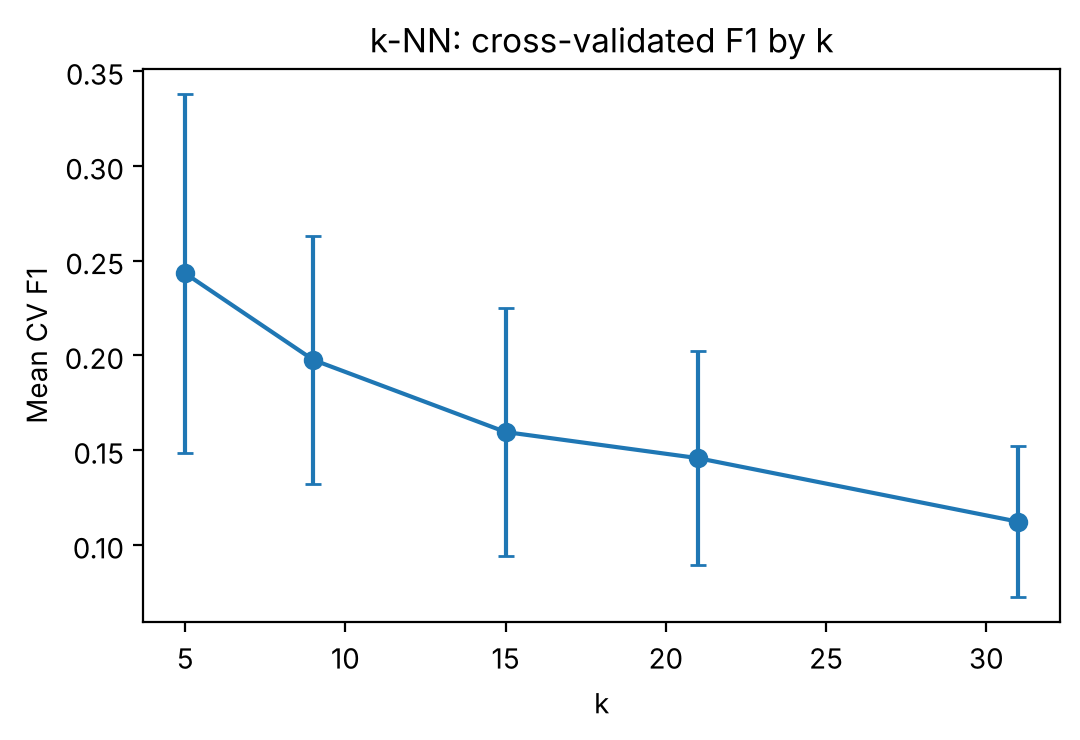

Tuned k-NN on test set (threshold 0.5):
  Precision: 0.462
  Recall:    0.13
  F1:        0.203
  ROC-AUC:   0.631


In [14]:
plt.figure(figsize=(5.5, 3.8))
plt.errorbar(cv_res.index, cv_res["mean CV F1"], yerr=cv_res["std CV F1"], marker="o", capsize=3)
plt.xlabel("k")
plt.ylabel("Mean CV F1")
plt.title("k-NN: cross-validated F1 by k")
plt.tight_layout()
plt.savefig("figures/knn_cv_f1.png", dpi=150)
plt.show()

best_knn = grid_search.best_estimator_
kp = best_knn.predict(X_test)
print("Tuned k-NN on test set (threshold 0.5):")
print("  Precision:", round(precision_score(y_test, kp, zero_division=0), 3))
print("  Recall:   ", round(recall_score(y_test, kp), 3))
print("  F1:       ", round(f1_score(y_test, kp), 3))
print("  ROC-AUC:  ", round(roc_auc_score(y_test, best_knn.predict_proba(X_test)[:, 1]), 3))

In [15]:
# 5-fold CV of the other models too, for a fair comparison (training data only)
scoring = {"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
cv_rows = []
for name in ["Logistic Regression", "LDA"]:
    pipe = Pipeline([("prep", preprocess), ("model", models[name])])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows.append({"Model": name, **{k: s[f"test_{k}"].mean() for k in scoring}})
s = cross_validate(best_knn, X_train, y_train, cv=cv, scoring=scoring)
cv_rows.append({"Model": "k-NN (tuned k=5)", **{k: s[f"test_{k}"].mean() for k in scoring}})
pd.DataFrame(cv_rows).set_index("Model")

,precision,recall,f1,roc_auc
Model,,,,
Logistic Regression,0.539,0.164,0.248,0.744
LDA,0.554,0.179,0.266,0.743
k-NN (tuned k=5),0.367,0.186,0.243,0.605


Smaller k gave the best CV F1 (k = 5), and F1 gets steadily worse as k grows. With a larger k, each prediction averages over more neighbours, and since most neighbours are non-escalated, the model rarely predicts the minority class. After tuning, k-NN's CV F1 (0.243) is about the same as logistic regression (0.248) and LDA (0.266) at the default threshold, so on F1 alone the three are hard to separate. But k-NN is clearly worse on ROC-AUC (0.605 vs about 0.744 in CV, and 0.631 vs 0.811 on the test set), meaning it ranks tickets by risk less well. Since a ranking is what we need to pick a lower threshold, I still prefer logistic regression/LDA. Also, k=5 has the highest fold-to-fold spread (std about 0.09), so I would not read too much into small F1 differences.

## 9. Bayes' theorem in the ticket scenario

For a ticket with features **x**:

- **Prior** P(escalated): how likely a ticket is to be escalated *before* we look at its details. Here it is about 0.21 (the escalation rate in the data).
- **Likelihood** P(x | escalated): how likely we are to see these features (e.g. high complexity, low team experience) *given* the ticket was escalated. Compare with P(x | not escalated).
- **Evidence** P(x): how common these features are overall, across all tickets. It is P(x|esc)P(esc) + P(x|not esc)P(not esc), and it just normalises the result.
- **Posterior** P(escalated | x): the updated probability that this particular ticket escalates after seeing its features:

  P(escalated | x) = P(x | escalated) · P(escalated) / P(x)

LDA uses this directly (Gaussian likelihoods with a shared covariance, combined with the prior), and logistic regression models the posterior directly. Example: a complex ticket handled by a junior team is more common among escalated tickets than among non-escalated ones, so its posterior is higher than the 0.21 prior.

## 10. Cost-sensitive decision rule

Let the posterior be p = P(escalated | x) = 0.30, with cost of a false positive = 1 and cost of a false negative = 5.

**Expected cost of escalating (predict 1):** we are wrong only if the ticket is *not* escalated, which has probability 1 − p = 0.70, and then we pay the FP cost:

E[cost | predict 1] = (1 − p) × 1 = 0.70 × 1 = **0.70**

**Expected cost of not escalating (predict 0):** we are wrong if the ticket *is* escalated, with probability p = 0.30, and then we pay the FN cost:

E[cost | predict 0] = p × 5 = 0.30 × 5 = **1.50**

Since 0.70 < 1.50, the lower-cost decision is to **escalate** (predict 1), even though the posterior is only 0.30 (well under 0.5).

**General threshold:** predict 1 whenever the expected cost of escalating is smaller:

(1 − p) · C_FP < p · C_FN
C_FP − p · C_FP < p · C_FN
C_FP < p (C_FN + C_FP)
**p > C_FP / (C_FP + C_FN) = 1 / (1 + 5) = 1/6 ≈ 0.167**

So the cost-sensitive threshold is about 0.167, much lower than 0.5. This is consistent with what we saw empirically: the best threshold in the table was the lowest one tested (0.20), far below 0.50. On the test set the exact 0.167 threshold gave a slightly higher cost (109) than 0.20 (98), but that difference comes from only a few tickets, so with 46 positives I would not treat it as meaningful. The theoretical rule is a good starting point, but it assumes the predicted probabilities are well calibrated.

In [16]:
# Quick numeric check of the derivation, and of the cost at the theoretical threshold
p, c_fp, c_fn = 0.30, 1, 5
print("Expected cost of escalating:    ", (1 - p) * c_fp)
print("Expected cost of not escalating:", p * c_fn)
t_star = c_fp / (c_fp + c_fn)
print("Cost-sensitive threshold:", round(t_star, 4))

pred_star = (probs >= t_star).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_star).ravel()
print(f"Test set at threshold {t_star:.3f}: FP={fp}, FN={fn}, cost={5*fn+fp}, "
      f"precision={precision_score(y_test, pred_star):.3f}, recall={recall_score(y_test, pred_star):.3f}")

Expected cost of escalating:     0.7
Expected cost of not escalating: 1.5
Cost-sensitive threshold: 0.1667
Test set at threshold 0.167: FP=69, FN=8, cost=109, precision=0.355, recall=0.826


## 11. Final comparison of all models under the cost function

In [17]:
cost_rows = []
for name, pipe in fitted.items():
    pred = pipe.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    cost_rows.append({"Model": name, "Threshold": 0.50, "FP": fp, "FN": fn, "Cost (5*FN + FP)": 5 * fn + fp})

for name in ["Logistic Regression", "LDA", "k-NN (k=15)"]:
    pr = fitted[name].predict_proba(X_test)[:, 1]
    pred = (pr >= 0.20).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    cost_rows.append({"Model": name, "Threshold": 0.20, "FP": fp, "FN": fn, "Cost (5*FN + FP)": 5 * fn + fp})

pd.DataFrame(cost_rows).set_index(["Model", "Threshold"])

,,FP,FN,Cost (5*FN + FP)
Model,Threshold,,,
Majority baseline,0.5,0,46,230
Logistic Regression,0.5,3,37,188
LDA,0.5,3,37,188
k-NN (k=15),0.5,4,42,214
Logistic Regression,0.2,48,10,98
LDA,0.2,50,9,95
k-NN (k=15),0.2,86,12,146


Lowering the threshold to 0.20 cuts the cost for logistic regression and LDA a lot compared with 0.50, and both beat k-NN and the baseline at either threshold. LDA is 3 cost points lower than logistic regression at 0.20 (95 vs 98), which is too small to matter.

## 12. Recommendation

Based on my results, I would recommend logistic regression as the model, used with a lowered decision threshold of about 0.20 instead of the default 0.50.

**Model choice.** Logistic regression and LDA performed almost identically (ROC-AUC about 0.81 for both), and both were clearly better than k-NN (AUC 0.70, and only 0.63 after tuning k with cross-validation) and the majority-class baseline. LDA was a few points cheaper at 0.20 (95 vs 98), but that gap is tiny, so I picked logistic regression over LDA because it gives probabilities directly, its coefficients are easy to explain to a support team (higher complexity raises escalation risk, more team experience lowers it), and it is not tied to the Gaussian assumptions that LDA makes. Plain accuracy was misleading here: the baseline that never escalates anything gets about 79.6% accuracy but has zero recall, so it is useless.

**Threshold and error costs.** At the default 0.50 threshold logistic regression only catches 9 of 46 escalated tickets (recall 0.20), which means 37 missed escalations. If a missed escalation costs five times as much as an unnecessary one, that is a bad trade. Under the cost 5×FN + FP, the lowest test cost among the thresholds I tried was at 0.20 (cost 98, versus 188 at 0.50). The theory agrees: with a false-negative cost of 5 and a false-positive cost of 1, the cost-sensitive cut-off is 1/(1+5) ≈ 0.167, so thresholds around 0.17 to 0.20 make sense. The price is lower precision (0.43), so more than half of the flagged tickets will not really need escalation.

**Limitations.** The data is synthetic and the 5:1 cost ratio is only illustrative, so real costs must be measured. The test set has only 46 positive tickets, so the numbers are noisy. Choosing the threshold on the test set also makes the cost estimate optimistic, because the test set is no longer a fresh sample after I tuned on it; When I picked the threshold from training data instead (0.16), the test cost rose to 111, so a realistic estimate is about 110 and not 98. The model is also not very strong overall (AUC about 0.81), and the probabilities may not be well calibrated.

**Responsible use.** The model should help staff prioritise tickets, not make final decisions automatically. People may over-trust a score (automation bias), and variables like priority, channel or customer tenure could cause some groups of customers to be treated differently, so I would check performance and false-negative rates across those groups. Before deployment I would also test calibration, run a pilot with human review, monitor for data drift, and re-estimate the cost ratio with the business.

In [18]:
recommendation_word_count = 440
print("Recommendation word count:", recommendation_word_count)

Recommendation word count: 440
